# Camada Gold 3: Cliente x Contrato

Esta Gold olha para o relacionamento do cliente com a empresa: tipo de contrato, forma de pagamento, fatura digital e tempo de permanência. É aqui que o cancelamento aparece com mais força, e é aqui que juntamos o que as Golds 1 e 2 mostraram.

Pergunta principal desta camada: **como o contrato e o tempo de casa se relacionam com o cancelamento, e qual é o grupo de clientes com maior risco de sair?**

## Preparação

Mesma base, mesmas cores e mesmas funções de apoio das outras Golds.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df_silver = pd.read_csv('../Data/Silver/tabela_silver.csv')
df = df_silver.copy()

COR_BASE = '#4C6A92'
COR_CANCELA = '#C0504D'
COR_REFERENCIA = '#7F7F7F'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

TAXA_GERAL = df['Status_Cancelamento'].mean() * 100
print(f'Clientes: {len(df)} | Taxa geral de cancelamento: {TAXA_GERAL:.1f}%')


def brl(valor):
    """Formata número no padrão brasileiro: 5.125,40"""
    return f'{valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def comparar_medias(grupo_a, grupo_b):
    """Diferença de médias entre dois grupos com teste t de Welch.
    p-valor abaixo de 0,05 indica que a diferença dificilmente é obra do acaso."""
    t_stat, p_valor = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)
    return grupo_a.mean(), grupo_b.mean(), p_valor


def taxa_por_grupo(dados, coluna, ordem=None):
    tabela = dados.groupby(coluna, observed=True)['Status_Cancelamento'].agg(Clientes='size', Cancelaram='sum')
    tabela['Taxa_Cancelamento_%'] = (tabela['Cancelaram'] / tabela['Clientes'] * 100).round(1)
    return tabela.reindex(ordem) if ordem else tabela


def grafico_taxa(tabela, titulo, ax=None):
    """Barras horizontais com a taxa de cancelamento de cada grupo e a média geral como referência."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.6 * len(tabela) + 1.5))
    rotulos = [str(i) for i in tabela.index]
    barras = ax.barh(rotulos, tabela['Taxa_Cancelamento_%'], color=COR_CANCELA)
    ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in tabela['Taxa_Cancelamento_%']], padding=3)
    ax.axvline(TAXA_GERAL, color=COR_REFERENCIA, linestyle='--', linewidth=1)
    ax.text(TAXA_GERAL, len(tabela) - 0.5, f' média {TAXA_GERAL:.1f}%'.replace('.', ','), color=COR_REFERENCIA, fontsize=9, va='bottom')
    ax.set_xlim(0, max(tabela['Taxa_Cancelamento_%'].max(), TAXA_GERAL) * 1.25)
    ax.invert_yaxis()
    ax.set_xlabel('Taxa de cancelamento (%)')
    ax.set_title(titulo)
    return ax

Clientes: 5633 | Taxa geral de cancelamento: 26.7%


## Construção da tabela Gold

Além das colunas de perfil e de contrato, criamos:

- `Faixa_Tempo`: tempo de assinatura em faixas (até 6 meses, 7 a 12, 13 a 24 e depois de 12 em 12 meses até 72).
- `Pagamento_Automatico`: se o pagamento é feito por cartão ou transferência automática.
- `Grupo_Risco`: marca os clientes que juntam os três fatores de maior cancelamento encontrados nas Golds (contrato mensal, fibra óptica e cheque eletrônico). A coluna `Servico_Internet` entra na tabela só para montar esse grupo.

In [2]:
colunas = ['ID_Cliente', 'Genero', 'Idoso', 'Conjuge', 'Dependentes', 'Contrato', 'Forma_Pagamento',
           'Faturamento_Eletronico', 'Servico_Internet', 'Tempo_Assinatura', 'Valores_Mensais',
           'Status_Cancelamento']
gold_contrato = df[colunas].copy()

ORDEM_TEMPO = ['Até 6', '7 a 12', '13 a 24', '25 a 36', '37 a 48', '49 a 60', '61 a 72']
gold_contrato['Faixa_Tempo'] = pd.cut(gold_contrato['Tempo_Assinatura'],
                                      bins=[-1, 6, 12, 24, 36, 48, 60, 72], labels=ORDEM_TEMPO)

gold_contrato['Pagamento_Automatico'] = gold_contrato['Forma_Pagamento'].isin(
    ['Cartão de crédito automático', 'Transferência bancária automática'])

gold_contrato['Grupo_Risco'] = ((gold_contrato['Contrato'] == 'Mensal') &
                                (gold_contrato['Servico_Internet'] == 'Fibra óptica') &
                                (gold_contrato['Forma_Pagamento'] == 'Cheque eletrônico'))

ORDEM_CONTRATO = ['Mensal', 'Um ano', 'Dois anos']

gold_contrato.to_csv('../Data/Gold/gold_cliente_contrato.csv', index=False, encoding='utf-8-sig')
print('Formato:', gold_contrato.shape)
gold_contrato.head()

Formato: (5633, 15)


,ID_Cliente,Genero,Idoso,Conjuge,Dependentes,Contrato,Forma_Pagamento,Faturamento_Eletronico,Servico_Internet,Tempo_Assinatura,Valores_Mensais,Status_Cancelamento,Faixa_Tempo,Pagamento_Automatico,Grupo_Risco
0,4578-PHJYZ,Masculino,False,True,True,Um ano,Cheque eletrônico,True,DSL,52,68.75,False,49 a 60,False,False
1,6289-CPNLD,Masculino,False,True,True,Um ano,Cheque pelo correio,True,DSL,33,73.90,True,25 a 36,False,False
2,2682-KEVRP,Feminino,True,False,False,Um ano,Cheque pelo correio,True,Sem serviço de internet,22,20.05,False,13 a 24,False,False
3,5697-GOMBF,Feminino,True,True,True,Mensal,Cheque eletrônico,True,DSL,28,35.90,False,25 a 36,False,False
4,9717-QEBGU,Masculino,False,False,False,Mensal,Cheque eletrônico,True,Fibra óptica,2,70.30,False,Até 6,False,True


## Perguntas de orientação

1. Como a carteira se divide entre os tipos de contrato?
2. O tipo de contrato muda a taxa de cancelamento?
3. Como o tempo de permanência se relaciona com o cancelamento?
4. A forma de pagamento e a fatura digital influenciam o cancelamento?
5. Qual perfil de cliente escolhe cada tipo de contrato?
6. Juntando as três Golds, qual é o grupo de clientes com maior risco de cancelar?

### 1. Como a carteira se divide entre os tipos de contrato?

In [3]:
resumo_contrato = gold_contrato.groupby('Contrato').agg(
    Clientes=('ID_Cliente', 'count'),
    Tempo_Medio_Meses=('Tempo_Assinatura', 'mean'),
    Mensalidade_Media=('Valores_Mensais', 'mean')).reindex(ORDEM_CONTRATO).round(1)
resumo_contrato['% da carteira'] = (resumo_contrato['Clientes'] / len(gold_contrato) * 100).round(1)
resumo_contrato

,Clientes,Tempo_Medio_Meses,Mensalidade_Media,% da carteira
Contrato,,,,
Mensal,3099,18.2,66.3,55.0
Um ano,1187,41.8,65.0,21.1
Dois anos,1347,56.4,60.3,23.9


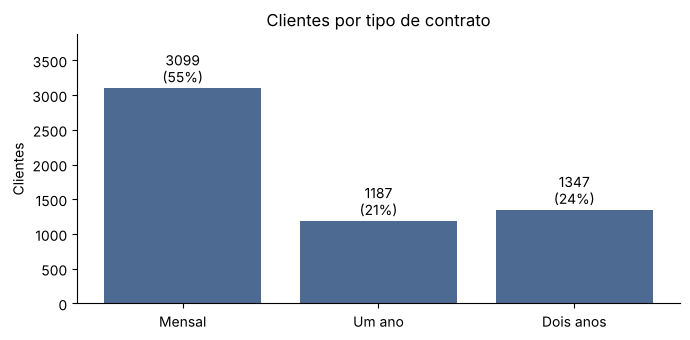

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.bar(resumo_contrato.index, resumo_contrato['Clientes'], color=COR_BASE)
ax.bar_label(barras, labels=[f'{c}\n({p:.0f}%)' for c, p in zip(resumo_contrato['Clientes'], resumo_contrato['% da carteira'])], padding=2)
ax.set_ylim(0, resumo_contrato['Clientes'].max() * 1.25)
ax.set_title('Clientes por tipo de contrato')
ax.set_ylabel('Clientes')
plt.tight_layout()
plt.show()

**Resposta:** mais da metade da carteira (55%) está no contrato mensal, que não tem fidelidade. O restante se divide quase igualmente entre um ano (21%) e dois anos (24%).

A mensalidade média é parecida nos três contratos (entre 60 e 66). O que muda muito é o tempo de casa: 18 meses em média no mensal, 42 no anual e 56 no de dois anos.

### 2. O tipo de contrato muda a taxa de cancelamento?

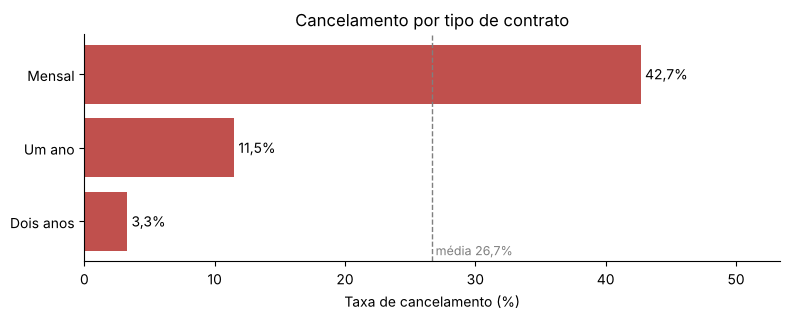

,Clientes,Cancelaram,Taxa_Cancelamento_%
Contrato,,,
Mensal,3099,1322,42.7
Um ano,1187,137,11.5
Dois anos,1347,44,3.3


In [5]:
taxa_contrato = taxa_por_grupo(gold_contrato, 'Contrato', ORDEM_CONTRATO)
grafico_taxa(taxa_contrato, 'Cancelamento por tipo de contrato')
plt.tight_layout()
plt.show()
taxa_contrato

In [6]:
cancelados = gold_contrato[gold_contrato['Status_Cancelamento']]
print(f"Dos {len(cancelados)} clientes que cancelaram, {(cancelados['Contrato'] == 'Mensal').mean():.0%} tinham contrato mensal.")

Dos 1503 clientes que cancelaram, 88% tinham contrato mensal.


**Resposta:** muda, e é a maior diferença de todo o projeto. No contrato mensal, 43% dos clientes cancelaram. No anual, 12%. No de dois anos, só 3%.

Como o mensal também é o contrato da maioria, ele concentra 88% de todos os cancelamentos da base. Na prática, o problema de churn da Terra Signal é um problema do contrato mensal.

### 3. Como o tempo de permanência se relaciona com o cancelamento?

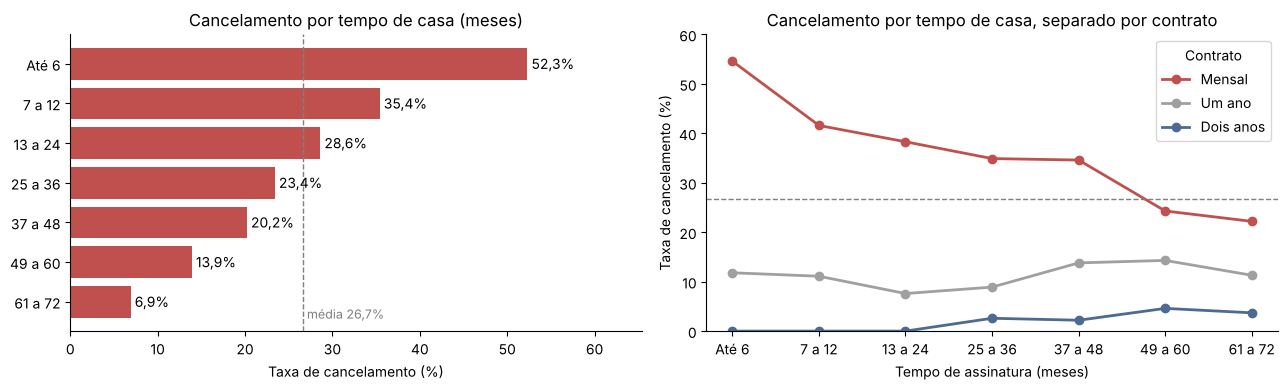

Contrato,Mensal,Um ano,Dois anos
Faixa_Tempo,,,
Até 6,54.6,11.8,0.0
7 a 12,41.6,11.1,0.0
13 a 24,38.3,7.6,0.0
25 a 36,34.9,8.9,2.6
37 a 48,34.6,13.8,2.2
49 a 60,24.3,14.3,4.6
61 a 72,22.2,11.3,3.7


In [7]:
taxa_tempo = taxa_por_grupo(gold_contrato, 'Faixa_Tempo', ORDEM_TEMPO)
taxa_tempo_contrato = (gold_contrato.groupby(['Faixa_Tempo', 'Contrato'], observed=True)['Status_Cancelamento']
                       .mean().unstack()[ORDEM_CONTRATO] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
grafico_taxa(taxa_tempo, 'Cancelamento por tempo de casa (meses)', ax=axes[0])

for contrato, cor in zip(ORDEM_CONTRATO, [COR_CANCELA, '#A0A0A0', COR_BASE]):
    axes[1].plot(taxa_tempo_contrato.index, taxa_tempo_contrato[contrato], marker='o', color=cor,
                 label=contrato, linewidth=2)
axes[1].axhline(TAXA_GERAL, color=COR_REFERENCIA, linestyle='--', linewidth=1)
axes[1].set_title('Cancelamento por tempo de casa, separado por contrato')
axes[1].set_xlabel('Tempo de assinatura (meses)')
axes[1].set_ylabel('Taxa de cancelamento (%)')
axes[1].set_ylim(0, 60)
axes[1].legend(title='Contrato')
plt.tight_layout()
plt.show()

taxa_tempo_contrato

In [8]:
print(f"Dos clientes que cancelaram, {(cancelados['Tempo_Assinatura'] <= 12).mean():.0%} saíram no primeiro ano.")

Dos clientes que cancelaram, 55% saíram no primeiro ano.


**Resposta:** o risco de cancelar é maior no começo e cai mês a mês. Nos primeiros 6 meses, 52% dos clientes cancelaram; depois de 5 anos, só 7%. Mais da metade de todos os cancelamentos (55%) acontece no primeiro ano.

O gráfico da direita mostra que isso vale principalmente para o contrato mensal: começa em 55% e mesmo depois de 5 anos ainda fica em 22%. Nos contratos de um e dois anos, a taxa fica baixa em qualquer momento. Ou seja, os primeiros meses do cliente mensal são o momento mais crítico da carteira.

### 4. A forma de pagamento e a fatura digital influenciam o cancelamento?

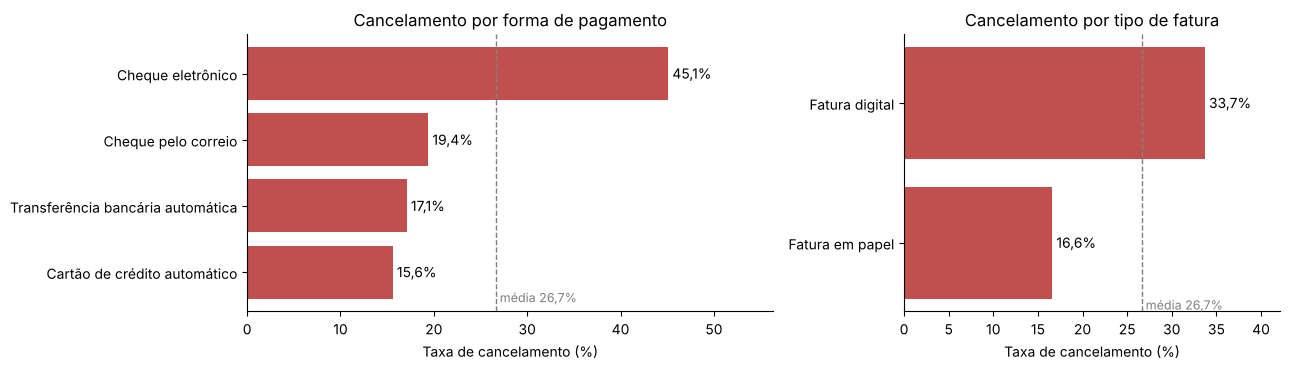

In [9]:
ordem_pagamento = ['Cheque eletrônico', 'Cheque pelo correio', 'Transferência bancária automática', 'Cartão de crédito automático']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1.4, 1]})
grafico_taxa(taxa_por_grupo(gold_contrato, 'Forma_Pagamento', ordem_pagamento), 'Cancelamento por forma de pagamento', ax=axes[0])
fatura = taxa_por_grupo(gold_contrato, 'Faturamento_Eletronico', [True, False])
fatura.index = ['Fatura digital', 'Fatura em papel']
grafico_taxa(fatura, 'Cancelamento por tipo de fatura', ax=axes[1])
plt.tight_layout()
plt.show()

Como o cheque eletrônico é muito usado no contrato mensal (78% de quem paga assim é mensal), conferimos se o efeito continua quando olhamos só os clientes mensais:

In [10]:
mensais = gold_contrato[gold_contrato['Contrato'] == 'Mensal']
taxa_por_grupo(mensais, 'Forma_Pagamento', ordem_pagamento)

,Clientes,Cancelaram,Taxa_Cancelamento_%
Forma_Pagamento,,,
Cheque eletrônico,1464,784,53.6
Cheque pelo correio,711,225,31.6
Transferência bancária automática,475,162,34.1
Cartão de crédito automático,449,151,33.6


**Resposta:** sim. O cheque eletrônico tem 45% de cancelamento, mais que o dobro das formas automáticas (cerca de 16%). E não é só porque ele aparece mais no contrato mensal: mesmo olhando só os mensais, quem paga com cheque eletrônico cancela 54%, contra cerca de 33% das outras formas. Alguns feedbacks de clientes também citam atraso no processamento desse tipo de pagamento.

A fatura digital também aparece com mais cancelamento (34% contra 17%). Aqui a leitura precisa de cuidado: é pouco provável que a fatura digital cause a saída. O mais provável é que ela seja mais comum entre clientes mais conectados, que usam fibra e comparam mais as ofertas do mercado.

### 5. Qual perfil de cliente escolhe cada tipo de contrato?

In [11]:
perfil = {}
for coluna, nome in [('Idoso', 'Idosos'), ('Conjuge', 'Com cônjuge'), ('Dependentes', 'Com dependentes')]:
    perfil[nome] = gold_contrato[gold_contrato[coluna]]['Contrato'].value_counts(normalize=True)
    perfil[nome.replace('Com', 'Sem') if 'Com' in nome else 'Não idosos'] = \
        gold_contrato[~gold_contrato[coluna]]['Contrato'].value_counts(normalize=True)
perfil = (pd.DataFrame(perfil).T[ORDEM_CONTRATO] * 100).round(1)
perfil = perfil.loc[['Idosos', 'Não idosos', 'Com cônjuge', 'Sem cônjuge', 'Com dependentes', 'Sem dependentes']]
perfil

Contrato,Mensal,Um ano,Dois anos
Idosos,71.1,16.3,12.6
Não idosos,51.8,22.0,26.1
Com cônjuge,40.6,24.4,35.0
Sem cônjuge,68.5,18.0,13.5
Com dependentes,36.9,24.9,38.3
Sem dependentes,62.8,19.5,17.8


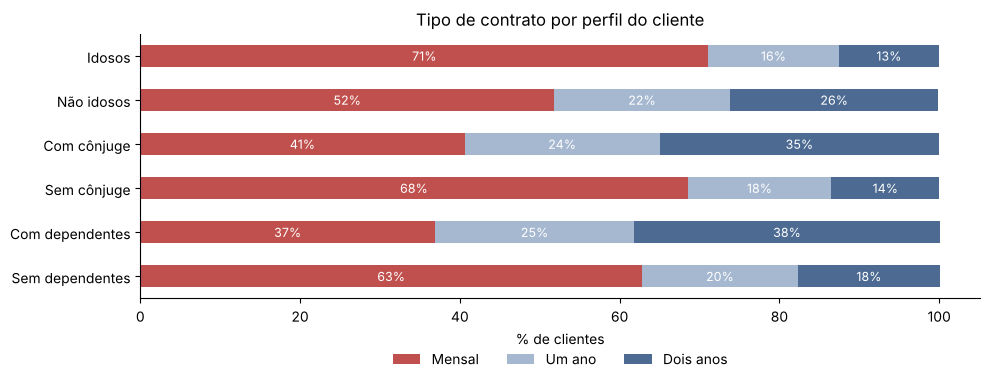

In [12]:
ax = perfil.plot(kind='barh', stacked=True, figsize=(10, 4), color=[COR_CANCELA, '#A5B8D0', COR_BASE])
for barras in ax.containers:
    ax.bar_label(barras, labels=[f'{v:.0f}%' for v in barras.datavalues], label_type='center', color='white', fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('% de clientes')
ax.set_title('Tipo de contrato por perfil do cliente')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
plt.show()

**Resposta:** os idosos são os que mais ficam no contrato mensal (71%), o que explica a taxa de cancelamento de 42% desse grupo. Clientes sem cônjuge (69% no mensal) e sem dependentes (63%) seguem o mesmo caminho.

Quem tem cônjuge ou dependentes divide-se de forma mais equilibrada e escolhe muito mais o contrato de dois anos (35% a 38%). Isso fecha o que apareceu na Gold 1: quem tem dependentes fica mais tempo como cliente, e o motivo é o contrato mais longo.

### 6. Juntando as três Golds, qual é o grupo de clientes com maior risco de cancelar?

Cada Gold apontou um fator forte: fibra óptica (Gold 2), contrato mensal e cheque eletrônico (Gold 3). Aqui vemos o que acontece quando eles se somam.

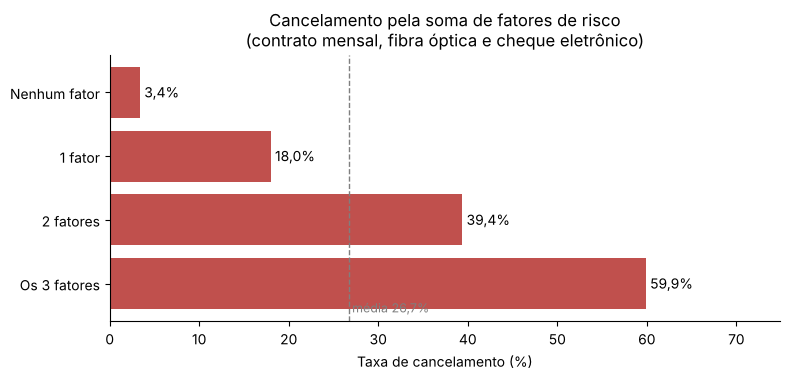

,Clientes,Cancelaram,Taxa_Cancelamento_%,% dos cancelamentos
Nenhum fator,1568,53,3.4,3.5
1 fator,1705,307,18.0,20.4
2 fatores,1322,521,39.4,34.7
Os 3 fatores,1038,622,59.9,41.4


In [13]:
fatores = pd.DataFrame({
    'Mensal': gold_contrato['Contrato'] == 'Mensal',
    'Fibra': gold_contrato['Servico_Internet'] == 'Fibra óptica',
    'Cheque eletrônico': gold_contrato['Forma_Pagamento'] == 'Cheque eletrônico',
})
gold_contrato['Qtd_Fatores_Risco'] = fatores.sum(axis=1)
taxa_fatores = taxa_por_grupo(gold_contrato, 'Qtd_Fatores_Risco', [0, 1, 2, 3])
taxa_fatores.index = ['Nenhum fator', '1 fator', '2 fatores', 'Os 3 fatores']
taxa_fatores['% dos cancelamentos'] = (taxa_fatores['Cancelaram'] / gold_contrato['Status_Cancelamento'].sum() * 100).round(1)

grafico_taxa(taxa_fatores, 'Cancelamento pela soma de fatores de risco\n(contrato mensal, fibra óptica e cheque eletrônico)')
plt.tight_layout()
plt.show()
taxa_fatores

**Resposta:** o grupo de maior risco é o cliente com **contrato mensal, internet de fibra e pagamento por cheque eletrônico**. São 1.038 clientes (18% da carteira), com 60% de cancelamento, e eles sozinhos respondem por 41% de todos os cancelamentos da base.

No outro extremo, quem não tem nenhum dos três fatores quase não cancela. A taxa sobe de forma clara a cada fator somado, o que mostra que os achados das três Golds se completam em vez de se repetirem.

## Conclusões da Gold 3

- O contrato é o fator mais ligado ao cancelamento: 43% no mensal contra 3% no de dois anos. O mensal concentra 88% dos cancelamentos.
- O primeiro ano é o período crítico: mais da metade dos cancelamentos acontece até o 12º mês.
- Cheque eletrônico cancela mais que o dobro das formas automáticas, mesmo dentro do contrato mensal.
- Idosos e clientes sem cônjuge ou dependentes estão mais no contrato mensal e, por isso, cancelam mais.
- O grupo mensal + fibra + cheque eletrônico reúne 18% dos clientes e 41% dos cancelamentos.

## Conclusão geral do projeto

Partimos da pergunta: **o que diferencia os clientes que cancelam dos que ficam na carteira da Terra Signal?**

| Fator | Fica mais | Cancela mais | Gold |
|---|---|---|---|
| Contrato | Dois anos (3%) | Mensal (43%) | 3 |
| Tempo de casa | Mais de 5 anos (7%) | Até 6 meses (52%) | 3 |
| Internet | Sem internet (7%) e DSL (19%) | Fibra óptica (42%) | 2 |
| Proteção e suporte | Com segurança online ou suporte (15%) | Sem eles (42%) | 2 |
| Pagamento | Automático (16%) | Cheque eletrônico (45%) | 3 |
| Mensalidade | Até 40 (12%) | 80 a 100 (38%) | 1 |
| Perfil | Com cônjuge/dependentes (15% a 20%) | Idosos (42%) | 1 e 3 |
| Gênero e renda | Sem diferença | Sem diferença | 1 |

A leitura que junta tudo: o cliente que cancela é, na maioria, alguém que entrou há pouco tempo, no contrato mensal, pagando caro por uma fibra óptica sem serviços de proteção ou suporte, e com uma forma de pagamento que gera atrito. Gênero e renda não ajudam a prever o cancelamento.

Com base nisso, as ações que os dados sustentam são:

1. **Levar clientes do mensal para contratos de um ou dois anos**, principalmente nos primeiros 12 meses, com algum benefício na troca.
2. **Oferecer segurança online e suporte técnico para clientes de fibra**, começando pelos idosos, que têm fibra mas quase não têm suporte.
3. **Estimular a troca do cheque eletrônico por pagamento automático**.
4. **Acompanhar de perto o grupo mensal + fibra + cheque eletrônico**, que concentra 41% dos cancelamentos.

Limitações: as análises mostram relações entre as variáveis, não provam causa. A renda mensal da base parece gerada de forma artificial (distribuição uniforme), por isso não foi usada nas conclusões. E os 277 valores totais e 18 tempos de assinatura estimados na Silver estão marcados nas colunas `Total_Estimado` e `Tempo_Estimado`, caso o grupo queira refazer alguma análise sem eles.